# 4. Attacks and defences

Because signals superpose before the server sees them, a single boosted device can steer the
over-the-air sum, and per-client defences (Krum, median, ...) have nothing to inspect. AirCompKit
models the adversary explicitly:

* a `ThreatModel` states **who** attacks, **what they know** (`knowledge`) and **how much power**
  they may add (`max_boost_db`). An attack that needs more knowledge than granted is rejected;
* attacks act on the array-level signal (`symbols="complex"`), where the server sees the whole
  $N\times L$ received block;
* defences decide how devices use the channel and how the server combines.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import aircompkit as ac

print("AirCompKit", ac.__version__)

AirCompKit 1.0.0


In [2]:
from aircompkit.adversary import ThreatModel

print("attacks :", ac.available("attack"))
print("defences:", ac.available("defense"))
try:
    ThreatModel(attack={"name": "collude", "boost_db": 15}, n_attackers=3)
except ValueError as e:
    print("rejected:", e)

attacks : ['collude', 'csi_spoof', 'gaussian', 'label_flip', 'misalign', 'scaled', 'sign_flip']
defences: ['digital_robust', 'genie', 'group_gm', 'none']
rejected: attack Collude needs knowledge ['honest_mean'] that the threat model does not grant (add it to 'knowledge')


## A secure OTA-FL experiment

20 devices, a 12-antenna server with the `maxmin` combiner, channel inversion, a synthetic task.
Three attackers flip the sign of their update and boost their power by 20 dB.

In [3]:
from aircompkit.learning import FederatedConfig, train
from aircompkit.learning.data import synthetic

data = synthetic(n_train=4000, n_test=1000, dim=20, n_classes=4, seed=4)
sc = ac.Scenario(devices={"name": "fixed", "K": 20, "p_max": 1.0},
                 channel={"name": "rayleigh", "n_rx": 12}, receiver="maxmin",
                 power_control="channel_inversion", noise_var=0.01, symbols="complex", seed=3)
base = {"dataset": data, "rounds": 40, "eval_every": 5, "lr": 0.2, "clip": 0.5,
        "model": {"name": "mlp", "hidden": [16]}}

def compare(threat):
    out = {"ideal": train(sc, FederatedConfig(**base, aggregation="ideal"))}
    for d in ("none", "group_gm", {"name": "digital_robust", "rule": "median"}, "genie"):
        name = d if isinstance(d, str) else "digital median"
        out[name] = train(sc, FederatedConfig(**base, threat=threat, defense=d))
    return out

sign = compare({"attack": {"name": "sign_flip", "boost_db": 20.0}, "n_attackers": 3})
for k, r in sign.items():
    print(f"{k:15s} accuracy {r['test_acc'][-1]:.3f}   channel uses/round {r['channel_uses'].mean():.0f}")

ideal           accuracy 0.981   channel uses/round 0
none            accuracy 0.241   channel uses/round 1
group_gm        accuracy 0.982   channel uses/round 8
digital median  accuracy 0.981   channel uses/round 20
genie           accuracy 0.982   channel uses/round 1


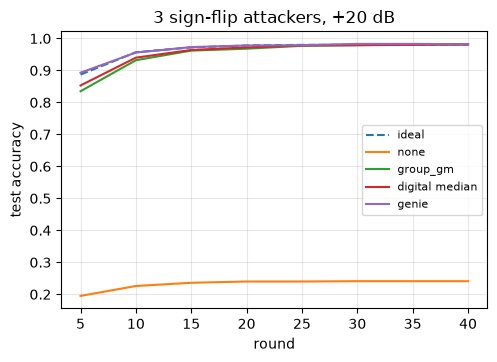

In [4]:
fig, ax = plt.subplots(figsize=(5.5, 3.6))
for k, r in sign.items():
    ax.plot(r["eval_round"], r["test_acc"], "--" if k == "ideal" else "-", label=k)
ax.set_xlabel("round"); ax.set_ylabel("test accuracy"); ax.set_title("3 sign-flip attackers, +20 dB")
ax.grid(alpha=0.3); ax.legend(fontsize=8); plt.show()

Plain AirComp collapses. Group geometric median and the digital median recover, at the cost of 8
and $K = 20$ channel uses per round. The `genie` knows the attackers and nulls them with the
combiner in **one** channel use: it marks what a detection-based defence could reach
([tutorial 5](05_custom_components.ipynb) writes one). The result records the attackers and,
for defences that flag devices, the detections per round:

In [5]:
r = sign["genie"]
print("attackers:", r.meta["attackers"])
print("flagged per round (mean): %.2f of 3,  false positives per round: %.3f"
      % (r["det_tp"].mean(), r["det_fp"].mean()))

attackers: [10, 12, 15]
flagged per round (mean): 3.00 of 3,  false positives per round: 0.000


## Omniscient colluders

`collude` attackers know the honest mean and all send the same vector opposite to it. That is a
rank-one attack, the hardest case for spatial detection, and it needs the `honest_mean` knowledge
flag:

In [6]:
coll = compare({"attack": {"name": "collude", "boost_db": 15.0}, "n_attackers": 3,
                "knowledge": ["own_data", "own_csi", "honest_mean"]})
for k, r in coll.items():
    print(f"{k:15s} accuracy {r['test_acc'][-1]:.3f}")

ideal           accuracy 0.981
none            accuracy 0.130
group_gm        accuracy 0.978
digital median  accuracy 0.980
genie           accuracy 0.982


## Privacy from receiver noise

The receiver noise in the AirComp estimate acts as a Gaussian mechanism. With clipped updates
(sensitivity = clip norm per device), the RDP accountant turns it into an $(\varepsilon,\delta)$
guarantee over the training rounds:

In [7]:
from aircompkit.metrics.privacy import aircomp_noise_std, gaussian_epsilon

for nv in (0.01, 0.1, 1.0):
    s = aircomp_noise_std(noise_var=nv, eta=1.0)
    print(f"noise_var {nv:5g}: epsilon after 40 rounds = {gaussian_epsilon(0.5, s, rounds=40):.3g} (delta 1e-5)")

noise_var  0.01: epsilon after 40 rounds = 1.22e+03 (delta 1e-5)
noise_var   0.1: epsilon after 40 rounds = 168 (delta 1e-5)
noise_var     1: epsilon after 40 rounds = 31.5 (delta 1e-5)


`examples/secure_otafl.py` runs a larger comparison of the defences on MNIST.
Next: [writing your own components](05_custom_components.ipynb).